In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from statsmodels.tsa.stattools import adfuller #check for day 2
from functools import wraps #for the decorator
import inspect #for the decorator
from scipy.linalg import null_space
from gauge_arbitrage.vf import vf_series
from gauge_arbitrage.vf import detector

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Day 2 (10/27)
Day 1 was skipped because we didn't have the timeline for that day. Note: going forward there are not going to be many functions in the notebook. Most functions for this week will be in vf.py (this is for functions related to V&F specifically)\
This week, we are focused on implementing V&F section 4 and testing their algorithm.
# Days 3-5 (10/28-10/30)
These days were spent implementing the algorithm (detector). I moved all of the functions to vf.py. The old functions are still at the bottom as a record.

In [4]:
B=vf_series.Vf_series(200, 200)
rng=np.random.default_rng(seed=0)

Text(0.5, 1.0, 'Simulation with 20 log-normal random walks (compare to V&F)')

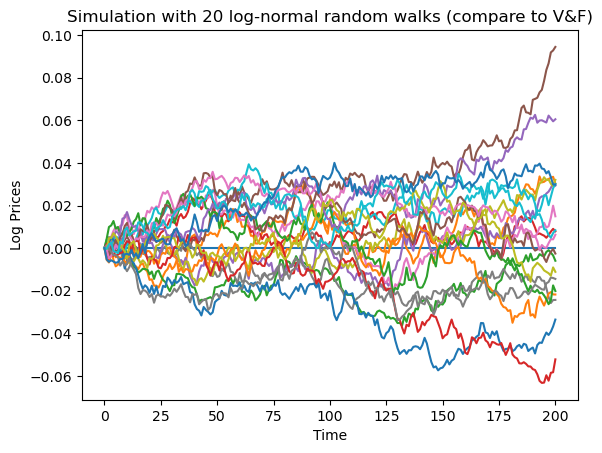

In [8]:
#test if the new package works (exact same code as 10_19.ipynb, but vf.X_mu_43)
beta_a=rng.uniform(low=-0.0001, high=0.0001, size=(18))                                        #Randomly generate values for beta
sigma=np.insert(rng.uniform(low=-0.001, high=0.001, size=(20, 18)),0,  np.zeros(18), axis=0)   #Randomly generate values for sigma
alpha_A=rng.uniform(low=-0.0001, high=0.0001, size=(2))                                        #Randomly generate values for alpha_A
Z=rng.standard_normal((200, 18))                #Randomly generate values for Brownian motions (only 18 independent Brownian motions)
X=B.X_mu_43(sigma, beta_a, alpha_A, 1, Z)       #Create the time series according to Eq. (106)

#Compare to V&F Figure 1
fig_1, ax_1=plt.subplots(1,1)
rng2=np.random.default_rng()

#plot 20 random walks
for i in range(21):
    ax_1.plot(B.times, np.log(X[:, i]))
ax_1.set_xlabel('Time')
ax_1.set_ylabel('Log Prices')
ax_1.set_title('Simulation with 20 log-normal random walks (compare to V&F)')

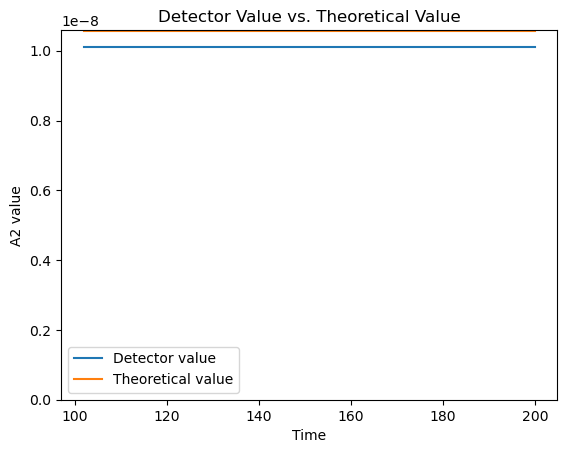

In [11]:
arr=detector.run_estimator(X, k=2)['A2'] # Run the detector
A2_values=arr[~np.isnan(arr)] #Remove nan values (window)

#This plot should match V&F figure 2
fig, ax=plt.subplots(1,1)
ax.plot(B.times[102:], A2_values, label='Detector value')
ax.plot(B.times[102:], np.zeros(99)+(alpha_A@alpha_A), label='Theoretical value')
ax.set_ylim(0)
ax.set_xlabel('Time')
ax.set_ylabel('A2 value')
ax.set_title("Detector Value vs. Theoretical Value")
ax.legend()

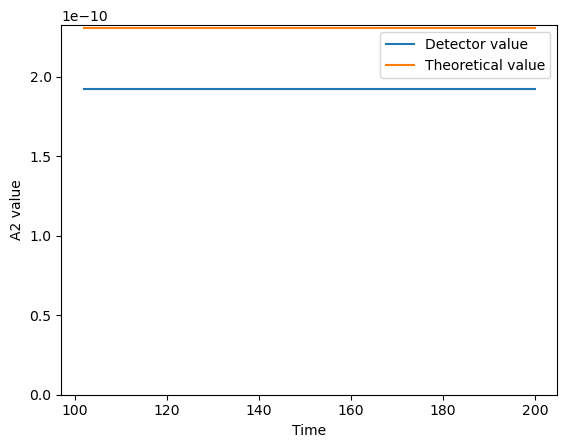

In [7]:
arr=detector.run_detector(detector.calc_R(X), L=100, refresh=5, n_dirs=2, use_cash=False)['products'] # Run the detector
A2_values=arr[~np.isnan(arr)] #Remove nan values (window)

#This plot should match V&F figure 2
fig, ax=plt.subplots(1,1)
ax.plot(B.times[102:], A2_values, label='Detector value')
ax.plot(B.times[102:], np.zeros(99)+(alpha_A@alpha_A), label='Theoretical value')
ax.set_ylim(0)
ax.set_xlabel('Time')
ax.set_ylabel('A2 value')
ax.legend()

In [62]:
############################################################
#Old functions
#i moved everything to vf.py but i want to keep this as a record
#equation 13/equation 85
def G_hat(Omega):
    N=Omega.shape[0]
    P=np.eye(N)-(1/N)*np.ones((N, N))
    return P @ Omega @ P

def zero_sum_basis(N):
    Q = np.zeros((N, N - 1))
    for i in range(1, N):
        Q[:i, i - 1] = 1.0 / np.sqrt(i * (i + 1))
        Q[i, i - 1] = -i / np.sqrt(i * (i + 1))
    return Q

def null_basis(G, k):
    N = G.shape[0]
    Q = zero_sum_basis(N)
    lam, V = np.linalg.eigh(Q.T @ G @ Q)        # (N-1) eigenpairs, ascending
    J = (Q @ V[:, :k]).T                         # back to R^N: k x N, orthonormal, each sums to 0
    return J, lam[:k], lam

#compute alpha A (equation 89)
#fix problems
#X (list containing all series) 2d array with mu (row), s (step)
#0<=s<=n-1
def alpha_hat(J, X, X_next, dt):
    r=(X_next-X)/X
    return J@r/dt

def align(J_new, J_prev):
    if J_prev is None:
        return J_new
    C_tilde = J_new @ J_prev.T                   # Eq. (120): overlaps between new and old bases
    U, _, Vt = np.linalg.svd(C_tilde)
    C_hat = U @ Vt                               # nearest orthogonal matrix to C_tilde
    return C_hat.T @ J_new                       # rotate new basis onto the old one

def run_estimator(X, L=100, k=1, dt=1.0):
    T, N = X.shape[0] - 1, X.shape[1]
    logret = np.diff(np.log(X), axis=0)          # T x N log-returns
    A2 = np.full(T + 1, np.nan)
    ah = [None] * (T + 1)
    lams = [None] * (T + 1)
    J_prev, a_prev = None, None
    for t in range(L, T):                        # window = returns ending at t; predict step t -> t+1
        R = logret[t - L:t]                      # L x N
        Omega_hat = np.cov(R, rowvar=False, bias=True) / dt     # Eq. (93), 1/L normalisation
        G = G_hat(Omega_hat)                                     # Eq. (85)
        J, lam_k, lam_all = null_basis(G, k)                     # Eqs. (86)-(88)
        J = align(J, J_prev)                                     # Appendix A
        a = alpha_hat(J, X[t], X[t + 1], dt)                     # Eq. (89), uses J(t) and the NEXT step
        if a_prev is not None:
            A2[t + 1] = a @ a_prev                               # Eq. (90): sum_A alpha^A(t) alpha^A(t+1)
        ah[t + 1], lams[t + 1] = a, lam_all
        J_prev, a_prev = J, a
    return {"A2": A2, "alpha_hat": ah, "lambdas": lams}

def make_market():
    pass

In [37]:
arr=detector.run_detector(detector.calc_R(X)-1, k=2)['weights']

In [39]:
arr.shape

(200, 2, 21)